# <center> TRABALHO DE CONCLUSÃO DE CURSO </center>
## <center> Especialização em Ciência de Dados - Turma 2018.1 - Facens </center>



|**Orientador:**|Fernando Vieira da Silva, M.Sc.|
|-----|-----------------------------------|

|**Nome:**|José Diniz Junior            |**RA:**|183134|
|-----|-----------------------------|---|------|
|**Nome:**|Roberto Leonardo Rodrigues   |**RA:**|060235|

Resumo:...

# 1 - Análise dos dados

Para o presente trabalho será utilizado um conjunto de datasets, sendo eles:

**Fotovoltaico.csv** - referente a dados da estação fotovoltaica composta por quatro inversores solares.

**Meteorologico.csv** - referente a dados da estação meteorológica.


In [1]:
#CÉLULA TCC-01
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter, MinuteLocator, DayLocator

In [2]:
#CÉLULA TCC-02
#Método responsável por carregar os arquivos csv's
def loadDataFile(fileName, DateTimeIndex):
    #Convertendo a coluna de data para index e para o formato de DateTime
    if DateTimeIndex:    
        return pd.read_csv(fileName, encoding='utf-8', index_col=0, parse_dates=[0])
    else:
        return pd.read_csv(fileName, encoding='utf-8')

In [3]:
#CÉLULA TCC-03
# Método responsável por salvar o arquivo em formato csv
def saveDataFile(dataFrame, fileName):
    dataFrame.to_csv(fileName, encoding='utf-8', sep=',', index=False)

In [4]:
#CÉLULA TCC-04
#Método responsável por plotar os dataFrames
def showDataPlot(dataFrame):
    #plt.plot(dfFT.index,dfFT.energia_dia, 'ro-')
    #plt.plot(dfFT.index,dfFT.potencia, 'b+-')
    plt.grid()
    plt.plot(dataFrame)
    plt.gca().legend(dataFrame.columns)
    plt.show()

## 1.1 - Análise do dataset fotovoltaico

In [5]:
#CÉLULA TCC-0
dataSetFotoVoltaico = ['Fotovoltaico_Jul_2018.csv','Fotovoltaico_Ago_2018.csv','Fotovoltaico_Sep_2018.csv']

In [6]:
#CÉLULA TCC-0
for idx, data in  enumerate(dataSetFotoVoltaico):
    path = '{}'.format(data)
    if idx == 0:
        dfRawFoto = loadDataFile(path, True)
    else:
        dfRawFoto = pd.concat([dfRawFoto, loadDataFile(path, True)])
dfRawFoto.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2108090 entries, 2018-07-01 00:00:01.590000 to 2018-09-01 00:00:02.713000
Data columns (total 8 columns):
painel           float64
energia_dia      float64
energia_ano      float64
energia_total    float64
potencia         float64
power_led        int64
solarnet_led     int64
solarweb_led     int64
dtypes: float64(5), int64(3)
memory usage: 144.8 MB


In [7]:
#CÉLULA TCC-
#Selecionando campos
dfRawFoto.drop({
    #'painel',#Campo representando cada inversor instalado, ou seja, 4 inversores, podendo ser 1,2,3 e 4;
    #'energia_dia',#Campo representando a energia acumulada por dia, retirado do próprio inversor (Wh);
    'energia_ano',#Campo representando a energia acumulada por ano (Wh);
    'energia_total',#Campo representando a energia acumulada desde o inicio da operação do painel (Wh);
    #'potencia', #Potência instantâne, é a potência da associação de módulos conectados ao inversor (W);
    'power_led', #Led ...
    'solarnet_led', #Led ...
    'solarweb_led' #Led ...
    },axis=1, inplace=True)

In [8]:
#CÉLULA TCC-
#Removendo campos vazios
dfRawFoto.dropna(inplace=True)

In [9]:
#CÉLULA TCC-
#Selecionando apenas o painel 1
dfRawFoto1 = dfRawFoto[dfRawFoto.painel == 1]

In [10]:
#CÉLULA TCC-
#Ordenando o data set pelo index, que representa o campo data
dfRawFoto1 = dfRawFoto1.sort_index()
dfRawFoto1.head()

,painel,energia_dia,potencia
data,,,
2018-07-01 00:00:06.897,1.0,45990.0,0.0
2018-07-01 00:00:10.697,1.0,45990.0,0.0
2018-07-01 00:00:28.477,1.0,45990.0,0.0
2018-07-01 00:00:48.993,1.0,45990.0,0.0
2018-07-01 00:01:07.387,1.0,45990.0,0.0


In [11]:
#CÉLULA TCC-
dfRawFoto1.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 523377 entries, 2018-07-01 00:00:06.897000 to 2018-09-30 23:58:49.283000
Data columns (total 3 columns):
painel         523377 non-null float64
energia_dia    523377 non-null float64
potencia       523377 non-null float64
dtypes: float64(3)
memory usage: 16.0 MB


In [12]:
#CÉLULA TCC-
dfRawFoto1['energia']  = dfRawFoto1['energia_dia'] - dfRawFoto1['energia_dia'].shift(1)

In [13]:
#CÉLULA TCC-
dfRawFoto1[dfRawFoto1 < 0] = 0

In [14]:
#CÉLULA TCC-
dfRawFoto1.drop({'energia_dia'},axis=1, inplace=True)

In [15]:
#CÉLULA TCC-
dfRawFoto1.fillna(0, inplace=True)

In [16]:
#CÉLULA TCC-
dfRawFoto1.isna().sum()

painel      0
potencia    0
energia     0
dtype: int64

In [17]:
dfRawFoto1.head()

,painel,potencia,energia
data,,,
2018-07-01 00:00:06.897,1.0,0.0,0.0
2018-07-01 00:00:10.697,1.0,0.0,0.0
2018-07-01 00:00:28.477,1.0,0.0,0.0
2018-07-01 00:00:48.993,1.0,0.0,0.0
2018-07-01 00:01:07.387,1.0,0.0,0.0


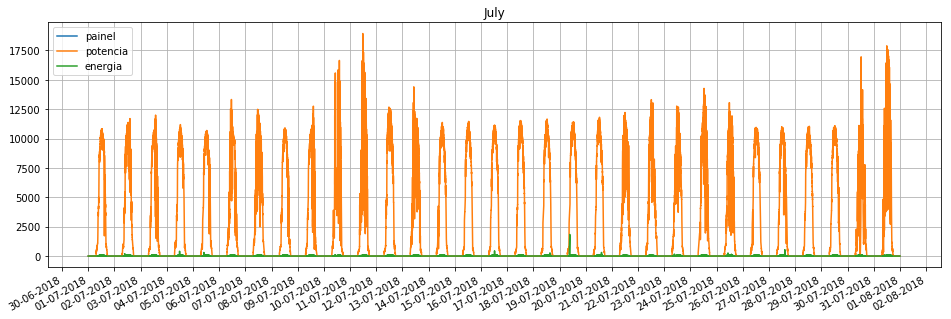

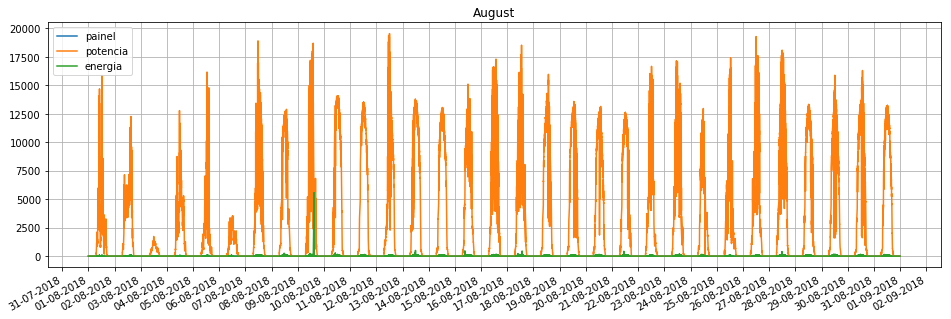

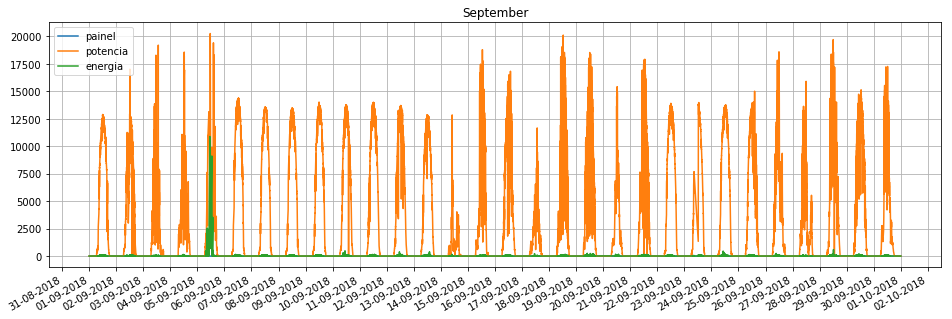

In [18]:
#CÉLULA TCC-
#deixar somente energia ????????
for m in dfRawFoto1.groupby(by=[dfRawFoto1.index.month]):
    plt.figure(figsize=(16,5))
    plt.grid()
    plt.plot(m[1])
    plt.title(m[1].index.month_name()[0])
    plt.gca().legend(m[1].columns)
    plt.gca().xaxis.set_major_locator(DayLocator())#DayLocator(interval=5)
    plt.gca().xaxis.set_major_formatter(DateFormatter('%d-%m-%Y'))
    plt.gcf().autofmt_xdate()
    plt.show()

In [19]:
a = dfRawFoto1.reset_index()[(dfRawFoto1.reset_index()['data'] >= '2018-09-05 09:00:00') & (dfRawFoto1.reset_index()['data'] <= '2018-09-05 19:00:00') ]
a.set_index('data',inplace=True)
a.head(50)

,painel,potencia,energia
data,,,
2018-09-05 09:01:11.360,1.0,2750.0,1390.0
2018-09-05 09:05:58.770,1.0,8023.0,480.0
2018-09-05 09:14:33.787,1.0,9762.0,1216.0
2018-09-05 09:14:39.127,1.0,8836.0,4.0
2018-09-05 09:14:39.680,1.0,8836.0,0.0
2018-09-05 09:14:40.333,1.0,10843.0,10.0
2018-09-05 09:14:41.513,1.0,10843.0,0.0
2018-09-05 09:14:41.677,1.0,10978.0,6.0
2018-09-05 09:21:43.737,1.0,10790.0,1020.0


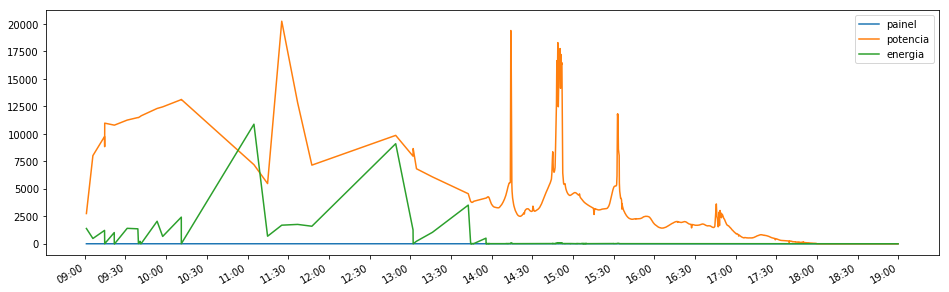

In [20]:
plt.figure(figsize=(16,5))
plt.grid()
#showDataPlot(dfRawFoto1)
##Dividir gráficos
plt.grid()
plt.plot(a)
plt.gca().legend(a.columns)
plt.gca().xaxis.set_major_locator(MinuteLocator(byminute=(0,30,0)))#DayLocator(interval=5)
plt.gca().xaxis.set_major_formatter(DateFormatter('%H:%M'))
plt.gcf().autofmt_xdate()
plt.show()

## 1.2 - Análise do dataset meteorológico

In [21]:
#CÉLULA TCC-0
dataSetMeteorologico = ['Meteorologico_Jul_2018.csv','Meteorologico_Ago_2018.csv','Meteorologico_Sep_2018.csv']

In [22]:
#CÉLULA TCC-0
for idx, data in  enumerate(dataSetMeteorologico):
    path = '{}'.format(data)
    if idx == 0:
        dfRawMete = loadDataFile(path, True)
    else:
        dfRawMete = pd.concat([dfRawMete, loadDataFile(path, True)])
dfRawMete.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 13120 entries, 2018-07-01 00:00:07 to 2018-09-01 00:00:06
Data columns (total 14 columns):
deficit_vapor_vmin         13120 non-null float64
deficit_vapor_vmedio       13120 non-null float64
ponto_orvalho_vmin         13120 non-null float64
ponto_orvalho_vmedio       13120 non-null float64
precipitacao_valor         13120 non-null float64
radiacao_solar_valor       13120 non-null float64
temperatura_ar_vmin        13120 non-null float64
temperatura_ar_vmedio      13120 non-null float64
temperatura_ar_vmax        13120 non-null float64
umidade_ar_vmin            13120 non-null float64
umidade_ar_vmedio          13120 non-null float64
umidade_ar_vmax            13120 non-null float64
velocidade_vento_vmedio    13120 non-null float64
velocidade_vento_vmax      13120 non-null float64
dtypes: float64(14)
memory usage: 1.5 MB


In [23]:
#CÉLULA TCC-
#Selecionando campos
dfRawMete.drop({
    #'deficit_vapor_vmin',
    #'deficit_vapor_vmedio',
    #'ponto_orvalho_vmin',
    #'ponto_orvalho_vmedio',
    #'precipitacao_valor',
    #'radiacao_solar_valor',
    #'temperatura_ar_vmin',#
    #'temperatura_ar_vmedio',
    #'temperatura_ar_vmax',#
    #'umidade_ar_vmin',#
    #'umidade_ar_vmedio',
    #'umidade_ar_vmax',#
    #'velocidade_vento_vmedio',
    #'velocidade_vento_vmax'
    },axis=1, inplace=True)

In [24]:
#CÉLULA TCC-
#Removendo campos vazios
dfRawMete.dropna(inplace=True)

In [25]:
#CÉLULA TCC-
dfRawMete.head()

,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
data,,,,,,,,,,,,,,
2018-07-01 00:00:07,0.32,0.33,11.7,11.7,0.0,0.0,15.12,15.18,15.24,79.73,80.27,80.82,0.0,0.0
2018-07-01 00:10:07,0.31,0.31,12.0,12.0,0.0,0.0,15.21,15.21,15.21,81.63,81.63,81.63,0.0,0.0
2018-07-01 00:20:07,0.32,0.32,12.0,12.0,0.0,0.0,15.17,15.18,15.19,81.42,81.43,81.44,0.0,0.0
2018-07-01 00:30:06,0.31,0.31,11.9,11.9,0.0,0.0,15.03,15.05,15.08,81.60,81.70,81.80,0.0,0.0
2018-07-01 00:40:07,0.28,0.29,11.9,11.9,0.0,0.0,14.79,14.90,15.01,82.36,82.62,82.89,0.0,0.0


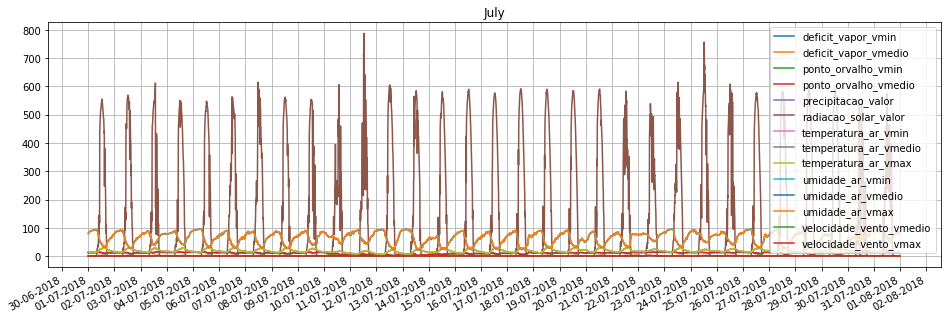

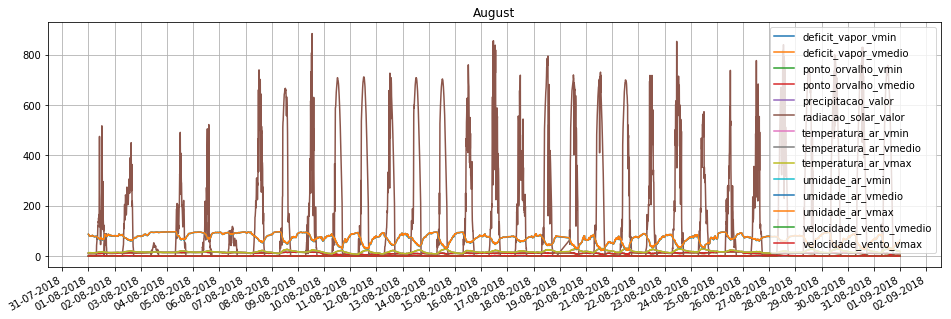

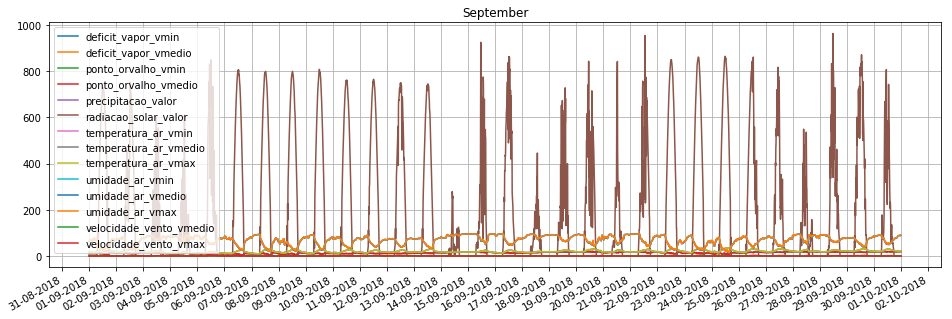

In [26]:
#CÉLULA TCC-
#plt.figure(figsize=(16,5))
#showDataPlot(dfRawMete)
for m in dfRawMete.groupby(by=[dfRawMete.index.month]):
    plt.figure(figsize=(16,5))
    plt.grid()
    plt.plot(m[1])
    plt.title(m[1].index.month_name()[0])
    plt.gca().legend(m[1].columns)
    plt.gca().xaxis.set_major_locator(DayLocator())#DayLocator(interval=5)
    plt.gca().xaxis.set_major_formatter(DateFormatter('%d-%m-%Y'))
    plt.gcf().autofmt_xdate()
    plt.show()

## 1.3 - Unificando os datasets

Como os datasets apresentam medições distintas em tempos e frequência diferentes, como demonstra a representação abaixo:
* Fotovoltaico - apresenta em média 1 medição a cada 15 a 20 segundos, totalizando 240 medições por hora;
* Meteorologico - apresenta em média 1 mediação a cada 10 minutos, totalizando 6 medições por hora;

Será utilizado a tecnica de UpSample para os dados fotovoltaicos afim de centralizar as medições em um tempo maior, e para os dados meteorológicos a tecnica de DownSample para ajustar as medições em períodos faltantes, visando também um mesmo padrão de tempo nos dois datasets.

In [27]:
#CÉLULA TCC-
#D         calendar day frequency
#H         hourly frequency
#T, min    minutely frequency
freq = '1D'

## 1.3.1 - DownSample

In [28]:
dfRawFoto1.head()

,painel,potencia,energia
data,,,
2018-07-01 00:00:06.897,1.0,0.0,0.0
2018-07-01 00:00:10.697,1.0,0.0,0.0
2018-07-01 00:00:28.477,1.0,0.0,0.0
2018-07-01 00:00:48.993,1.0,0.0,0.0
2018-07-01 00:01:07.387,1.0,0.0,0.0


In [29]:
#CÉLULA TCC-
downFoto = dfRawFoto1.resample(freq) #de 10 em 10 minutos cravados
newDownFoto = downFoto.agg({
    "painel":'max',
    "potencia":'mean',
    "energia":'sum'
})
interDownFoto = newDownFoto.interpolate(method='linear')
#interpolatedFT = tenMinutesFT.interpolate(method='spline', order=2)#polinomial
print(interDownFoto.head())

            painel     potencia  energia
data                                    
2018-07-01     1.0  2577.355035  50520.0
2018-07-02     1.0  2629.287852  52510.0
2018-07-03     1.0  2308.326910  43940.0
2018-07-04     1.0  2578.116348  50170.0
2018-07-05     1.0  2494.360807  48180.0


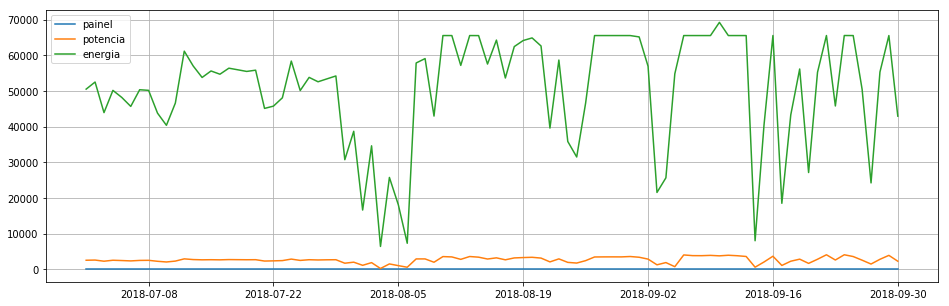

In [30]:
#CÉLULA TCC-
plt.figure(figsize=(16,5))
showDataPlot(interDownFoto)
##Dividir gráficos

## 1.3.2 - UpSample

In [31]:
#CÉLULA TCC-
downMete = dfRawMete.resample(freq) #de 10 em 10 minutos cravados
newDownMete = downMete.agg({
    'deficit_vapor_vmin':'min',
    'deficit_vapor_vmedio':'mean',
    'ponto_orvalho_vmin':'min',
    'ponto_orvalho_vmedio':'mean',
    'precipitacao_valor':'mean',
    'radiacao_solar_valor':'mean',
    'temperatura_ar_vmin':'min',
    'temperatura_ar_vmedio':'mean',
    'temperatura_ar_vmax':'max',
    'umidade_ar_vmin':'min',
    'umidade_ar_vmedio':'mean',
    'umidade_ar_vmax':'max',
    'velocidade_vento_vmedio':'mean',
    'velocidade_vento_vmax':'max'
})
interDownMete = newDownMete.interpolate(method='linear')
#interpolatedFT = tenMinutesFT.interpolate(method='spline', order=2)#polinomial
interDownMete.head(10)

,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
data,,,,,,,,,,,,,,
2018-07-01,0.09,0.938125,8.7,11.668750,0.000000,116.069444,12.84,19.110139,29.68,30.80,66.609861,93.91,0.102083,0.9
2018-07-02,0.11,1.084375,8.0,10.982639,0.000000,116.861111,12.26,19.573542,29.88,26.39,62.697222,92.34,0.226389,1.2
2018-07-03,0.15,0.786042,10.6,12.462500,0.000000,102.381944,12.48,18.720972,29.25,38.21,69.530069,89.16,0.623611,2.3
2018-07-04,0.15,0.841181,11.6,13.189583,0.000000,117.277778,14.42,19.696597,28.19,38.36,68.943333,90.58,0.422917,1.9
2018-07-05,0.07,0.963472,9.1,12.364583,0.001389,114.034722,12.89,19.731389,29.06,30.80,67.416667,94.96,0.116667,0.9
2018-07-06,0.17,1.099028,7.6,11.487500,0.000000,114.388889,13.68,20.220694,29.56,27.15,61.213681,88.85,0.081250,0.8
2018-07-07,0.18,0.998403,7.5,11.265278,0.000000,118.659722,13.85,19.483125,27.67,28.69,62.927083,88.34,0.252778,1.3
2018-07-08,0.17,1.112222,7.9,10.116667,0.000000,118.159722,12.25,19.291250,28.95,27.70,59.932778,88.09,0.168056,1.2
2018-07-09,0.14,0.800208,9.9,12.025694,0.001389,105.048611,12.39,18.529097,27.00,37.98,69.019653,90.40,0.293056,1.6


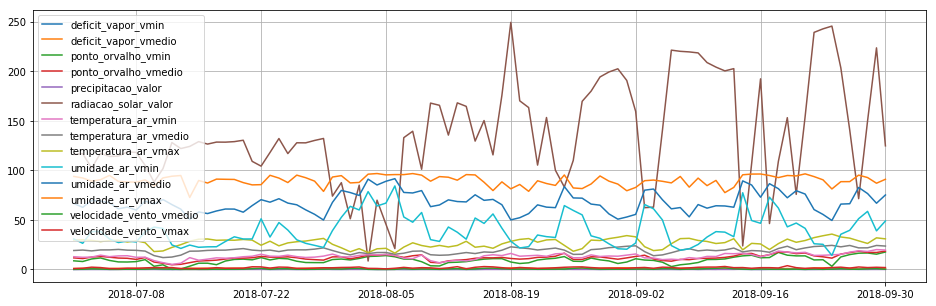

In [32]:
#CÉLULA TCC-
plt.figure(figsize=(16,5))
showDataPlot(interDownMete)
##Dividir gráficos

## 1.3.3 - Realizando o merge

Com os datasets padronizados na mesma freqência de medições, é possível realizar juntar ('merge') os dois em um só dataset, tornando o dataset mais interesssante por conter ambos os registros unificados. 

In [33]:
#CÉLULA TCC-
dfSet1 = pd.merge(interDownFoto, interDownMete, left_index=True, right_index=True)
#dfSet1['TotalSegundos'] = dfSet1.index.hour * 360 + dfSet1.index.minute * 60 + dfSet1.index.second
dfSet1.reset_index(inplace=True)

In [34]:
#CÉLULA TCC-
dfSet1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92 entries, 0 to 91
Data columns (total 18 columns):
data                       92 non-null datetime64[ns]
painel                     92 non-null float64
potencia                   92 non-null float64
energia                    92 non-null float64
deficit_vapor_vmin         92 non-null float64
deficit_vapor_vmedio       92 non-null float64
ponto_orvalho_vmin         92 non-null float64
ponto_orvalho_vmedio       92 non-null float64
precipitacao_valor         92 non-null float64
radiacao_solar_valor       92 non-null float64
temperatura_ar_vmin        92 non-null float64
temperatura_ar_vmedio      92 non-null float64
temperatura_ar_vmax        92 non-null float64
umidade_ar_vmin            92 non-null float64
umidade_ar_vmedio          92 non-null float64
umidade_ar_vmax            92 non-null float64
velocidade_vento_vmedio    92 non-null float64
velocidade_vento_vmax      92 non-null float64
dtypes: datetime64[ns](1), float64(17)
memor

In [35]:
#CÉLULA TCC-
saveDataFile(dfSet1,'FotoMet_P1_All_Day_2018.csv')
#saveDataFile(dfSet1,'input/FotoMet_P1_Sep_2018.csv')

In [36]:
#CÉLULA TCC-
dfSet1 = loadDataFile('FotoMet_P1_All_Day_2018.csv', False)
#dfSet1 = loadDataFile('input/FotoMet_P1_Sep_2018.csv', False)

In [37]:
#CÉLULA TCC-
dfSet1.describe()

,painel,potencia,energia,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
count,92.0,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000
mean,1.0,2692.368187,50697.489130,0.160109,0.874768,9.419565,12.025663,0.013327,136.351920,13.230326,19.078601,26.800543,39.519348,67.687661,89.753261,0.441216,1.703261
std,0.0,850.726493,15276.458143,0.092600,0.387258,3.542838,2.868230,0.038243,52.837021,2.850238,2.805350,4.418206,15.502713,10.057562,5.221702,0.353554,0.600998
min,1.0,267.643318,6447.000000,0.040000,0.140208,0.100000,4.705556,0.000000,8.506944,5.100000,11.975833,16.450000,14.180000,49.456923,72.650000,0.017483,0.600000
25%,1.0,2305.935037,43905.000000,0.090000,0.551349,7.300000,10.393783,0.000000,106.489583,11.815000,17.211713,23.752500,27.047500,61.132257,87.190000,0.191985,1.200000
50%,1.0,2722.671920,54760.000000,0.150000,0.877753,9.650000,11.804514,0.000000,128.784722,13.340000,19.419593,28.085000,36.540000,66.204479,90.170000,0.323077,1.700000
75%,1.0,3408.473090,64940.000000,0.200000,1.124730,11.350000,13.363112,0.001399,168.538996,14.847500,20.962185,29.915000,49.537500,73.371369,94.382500,0.636888,2.100000
max,1.0,4113.628066,69230.000000,0.430000,1.880909,17.600000,18.541958,0.216667,249.417582,20.050000,24.318392,35.690000,84.300000,91.623056,96.810000,1.635211,3.800000


In [38]:
dfSet1[(dfSet1['data'] >= '2018-09-05 00:00:00') & (dfSet1['data'] <= '2018-09-05 24:59:59')].energia.sum()

0.0

## 2 - Normalização

Descrição ...

In [39]:
#CÉLULA TCC-
df = dfSet1.drop(['data'],axis=1)

In [40]:
#CÉLULA TCC-
from sklearn.preprocessing import MinMaxScaler
min_max_scaler = MinMaxScaler()
df[df.columns] = min_max_scaler.fit_transform(df[df.columns])
df.describe()

,painel,potencia,energia,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
count,92.0,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000
mean,0.0,0.630456,0.704816,0.307971,0.421991,0.532547,0.529047,0.061509,0.530674,0.543835,0.575470,0.537970,0.361371,0.432355,0.707916,0.261931,0.344769
std,0.0,0.221199,0.243322,0.237435,0.222473,0.202448,0.207296,0.176508,0.219322,0.190651,0.227291,0.229636,0.221088,0.238522,0.216130,0.218550,0.187812
min,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.0,0.529979,0.596626,0.128205,0.236192,0.411429,0.411106,0.000000,0.406718,0.449164,0.424214,0.379548,0.183507,0.276889,0.601821,0.107869,0.187500
50%,0.0,0.638336,0.769524,0.282051,0.423706,0.545714,0.513064,0.000000,0.499263,0.551171,0.603097,0.604730,0.318882,0.397180,0.725166,0.188903,0.343750
75%,0.0,0.816652,0.931669,0.410256,0.565589,0.642857,0.625709,0.006455,0.664280,0.652007,0.728079,0.699844,0.504243,0.567148,0.899524,0.382886,0.468750
max,0.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [41]:
#from sklearn.preprocessing import StandardScaler
#scaler = StandardScaler()
#df[df.columns] = scaler.fit_transform(df[df.columns])
#df.describe()

## 3 - Treinamento do modelo

Descrição ...

In [42]:
#CÉLULA TCC-
import seaborn as sns

from sklearn import model_selection
from sklearn import linear_model
from sklearn.ensemble import RandomForestRegressor

from sklearn import metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [43]:
#CÉLULA TCC-
def showPairPlot(dataFrame):

    pairPlot = sns.pairplot(
        dataFrame,
        size=2.0,
        aspect=1.4,
        plot_kws=dict(edgecolor="k", linewidth=0.2),
        diag_kws=dict(shade=True),        
        diag_kind="kde",
    )               
                 
    fig = pairPlot.fig
    fig.subplots_adjust(top=0.95)
    fig.suptitle(
        'Análise de parâmetros', 
        fontsize=13, 
        fontweight='bold'
    )

In [44]:
#CÉLULA TCC-
def showHeatMap(dataFrame):
    
    fig, (ax) = plt.subplots(1, 1, figsize=(11,7))
    heatMap = sns.heatmap(
        dataFrame.corr(), 
        ax=ax,           
        cmap="coolwarm",
        annot=True, 
        fmt='.2f',
        linewidths=.07
    )

    fig.suptitle(
        'Correlação de parâmetros', 
        fontsize=13, 
        fontweight='bold'
    )

In [45]:
#CÉLULA TCC-
def showResultPlot(y_pred,y_test):
    plt.figure(figsize=(17,7))
    y_pred = y_pred.T

    plt.plot(range(len(y_pred)), y_pred, 'ro-')
    plt.plot(range(len(y_test)), y_test, 'b+-')
    plt.gca().legend(('Previsão','Real'))
    #plt.xticks(range(0,1150,50))
    plt.grid()
    plt.show()

In [46]:
#CÉLULA TCC-
def showResult(model, X_train, y_train, X_test, y_test):

    model.fit(X_train, y_train)
    y_pred_Train = model.predict(X_train)
    y_pred_Test = model.predict(X_test)

    #print(model)# exibição dos parametros utilizados no modelo
    print('------------------- TREINO -------------------------')
    print('MSE: {:.6f}'.format(metrics.mean_squared_error(y_train, y_pred_Train)))
    print('RMSE: {:.6f}'.format(np.sqrt(metrics.mean_squared_error(y_train, y_pred_Train))))
    #print('r²: {:.2f} %'.format(model.score(X_train, y_train) * 100))
    print('r²: {:.2f} %'.format(r2_score(y_train, y_pred_Train) * 100))
    print('MAE: {:.6f}'.format(mean_absolute_error(y_train, y_pred_Train)))
    print('------------------- TESTE ---------------------------')
    print('MSE: {:.6f}'.format(metrics.mean_squared_error(y_test, y_pred_Test)))
    print('RMSE: {:.6f}'.format(np.sqrt(metrics.mean_squared_error(y_test, y_pred_Test))))
    #print('r²: {:.2f} %'.format(model.score(X_test, y_test) * 100))
    print('r²: {:.2f} %'.format(r2_score(y_test, y_pred_Test) * 100))
    print('MAE: {:.6f}'.format(mean_absolute_error(y_test, y_pred_Test)))

    print('----------------------------------------------------')
    showResultPlot(y_pred_Test,y_test)
    return model

In [81]:
dfParameters = df.drop([
    'painel',
    #'potencia',#
    #'energia',#
    #'deficit_vapor_vmin',#
    #'deficit_vapor_vmedio',#
    'ponto_orvalho_vmin',
    'ponto_orvalho_vmedio',
    'precipitacao_valor',
    #'radiacao_solar_valor',
    #'temperatura_ar_vmin',#
    'temperatura_ar_vmedio',
    #'temperatura_ar_vmax',#
    #'umidade_ar_vmin',#
    'umidade_ar_vmedio',
    #'umidade_ar_vmax',#
    'velocidade_vento_vmedio',
    'velocidade_vento_vmax'
    ],axis=1)

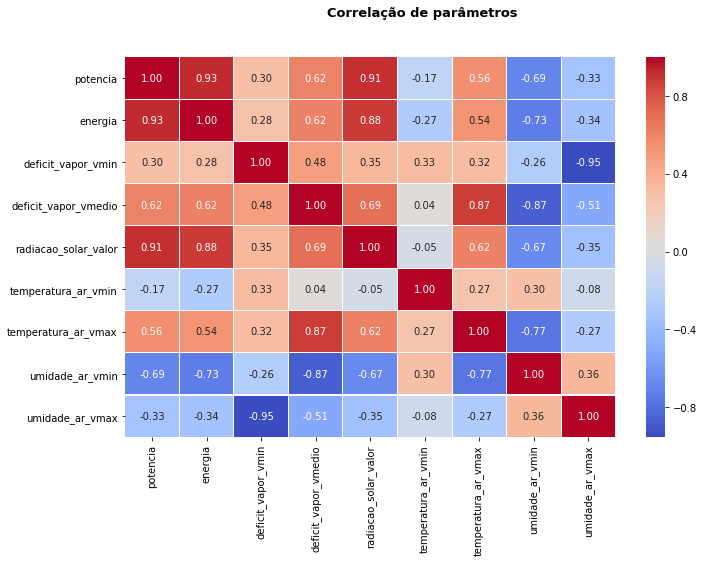

In [65]:
showHeatMap(dfParameters)

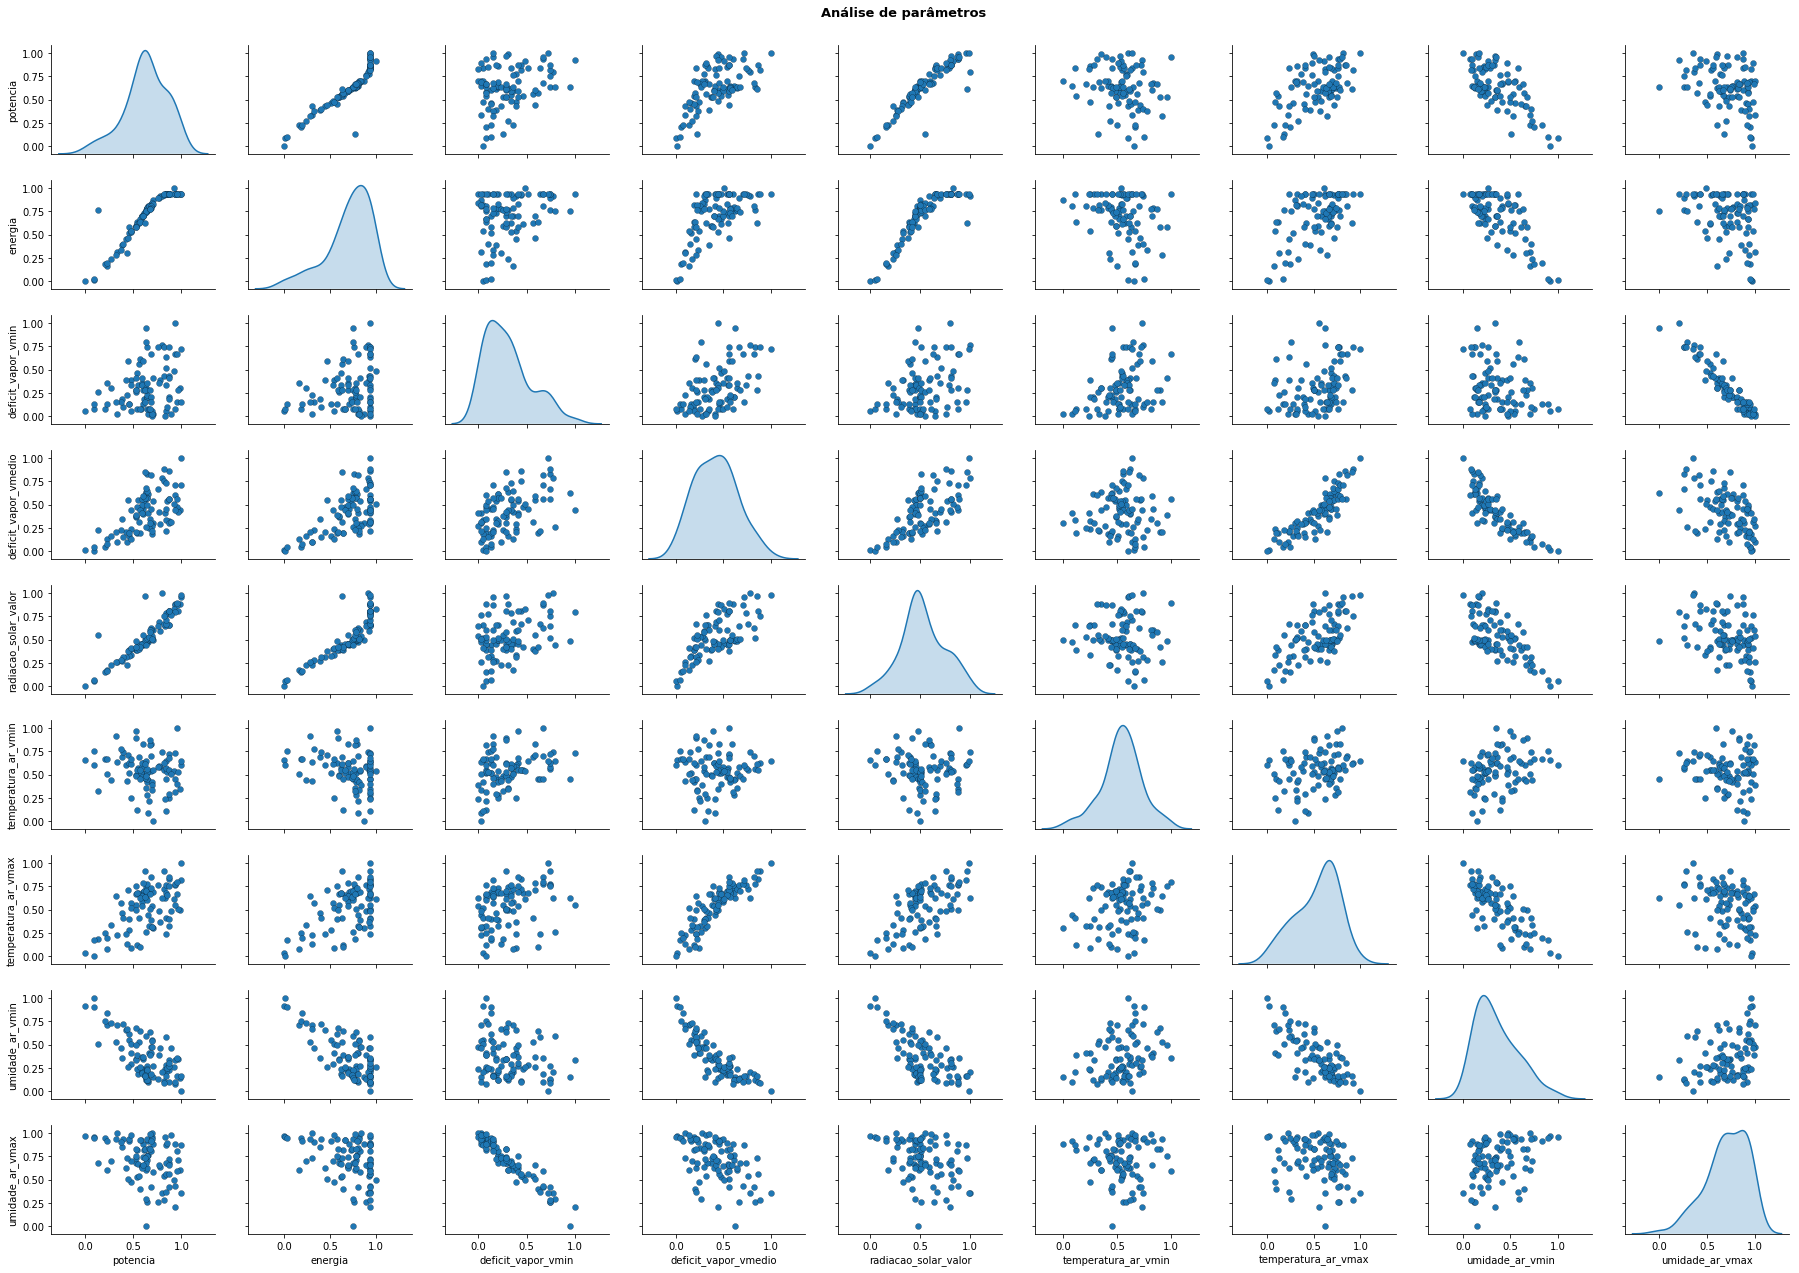

In [66]:
showPairPlot(dfParameters)

In [82]:
#CÉLULA TCC-
X = dfParameters.drop(['energia'],axis=1)
y = dfParameters.energia
X

,potencia,deficit_vapor_vmin,deficit_vapor_vmedio,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmax
0,0.600551,0.128205,0.458388,0.446483,0.517726,0.687630,0.237022,0.879967
1,0.614055,0.179487,0.542406,0.449769,0.478930,0.698025,0.174130,0.814983
2,0.530601,0.282051,0.371019,0.389667,0.493645,0.665281,0.342698,0.683361
3,0.600749,0.282051,0.402695,0.451499,0.623411,0.610187,0.344837,0.742136
4,0.578972,0.076923,0.472950,0.438037,0.521070,0.655405,0.237022,0.923427
5,0.552724,0.333333,0.550824,0.439507,0.573913,0.681393,0.184969,0.670530
6,0.588316,0.358974,0.493017,0.457235,0.585284,0.583160,0.206931,0.649421
7,0.595548,0.333333,0.558404,0.455160,0.478261,0.649688,0.192812,0.639073
8,0.524882,0.256410,0.379158,0.400736,0.487625,0.548337,0.339418,0.734685
9,0.474637,0.384615,0.238968,0.330805,0.253512,0.083160,0.407587,0.478891


In [83]:
#CÉLULA TCC-
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.25, random_state=42)

In [84]:
#CÉLULA TCC-
print(X_train.shape)
print(y_train.shape)

(69, 8)
(69,)


In [85]:
#CÉLULA TCC-
print(X_test.shape)
print(y_test.shape)

(23, 8)
(23,)


Regressão  Linear

https://towardsdatascience.com/linear-regression-in-python-9a1f5f000606

https://www.dataquest.io/blog/understanding-regression-error-metrics/

https://realpython.com/linear-regression-in-python/

https://www.analyticsvidhya.com/blog/2017/06/a-comprehensive-guide-for-linear-ridge-and-lasso-regression/

https://jovianlin.io/data-visualization-seaborn-part-2/

----------------------------------------------------
----------      REGRESSÃO LINEAR       -------------
----------------------------------------------------
------------------- TREINO -------------------------
MSE: 0.005776
RMSE: 0.075998
r²: 90.32 %
MAE: 0.056598
------------------- TESTE ---------------------------
MSE: 0.008344
RMSE: 0.091348
r²: 84.85 %
MAE: 0.069689
----------------------------------------------------


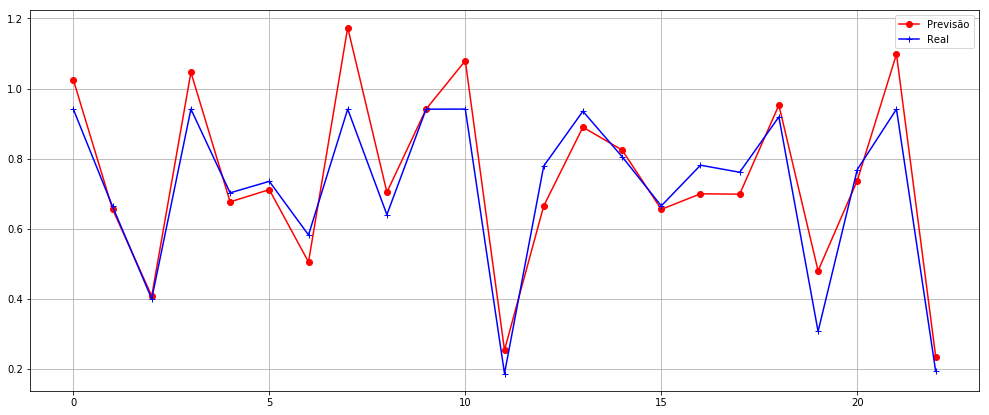

                      0  Coeficiente estimado
0              potencia              0.628630
3  radiacao_solar_valor              0.407098
5   temperatura_ar_vmax             -0.035016
1    deficit_vapor_vmin             -0.070830
4   temperatura_ar_vmin             -0.098207
7       umidade_ar_vmax             -0.120607
2  deficit_vapor_vmedio             -0.244990
6       umidade_ar_vmin             -0.298355


In [88]:
#CÉLULA TCC-
LinearRegression = linear_model.LinearRegression()

print('----------------------------------------------------')
print('----------      REGRESSÃO LINEAR       -------------')
print('----------------------------------------------------')
modelLinearRegression = showResult(LinearRegression, X_train, y_train, X_test, y_test)
#print(model.intercept_)
coeff = pd.DataFrame(X_train.columns)
coeff['Coeficiente estimado'] = pd.Series(modelLinearRegression.coef_)
coeff.sort_values(by='Coeficiente estimado', inplace=True, ascending=False)
print(coeff)
#print(modelRegLinear.coef_)
#for idx, col_name in enumerate(X_train.columns):
#    print("Ccoeficiente para a coluna '{}': {:.6f}".format(col_name, model.coef_[idx]))


Random Forest Regressor

----------------------------------------------------
------------      RANDOM FOREST     ----------------
----------------------------------------------------
------------------- TREINO -------------------------
MSE: 0.000465
RMSE: 0.021571
r²: 99.22 %
MAE: 0.011229
------------------- TESTE ---------------------------
MSE: 0.000843
RMSE: 0.029034
r²: 98.47 %
MAE: 0.020002
----------------------------------------------------


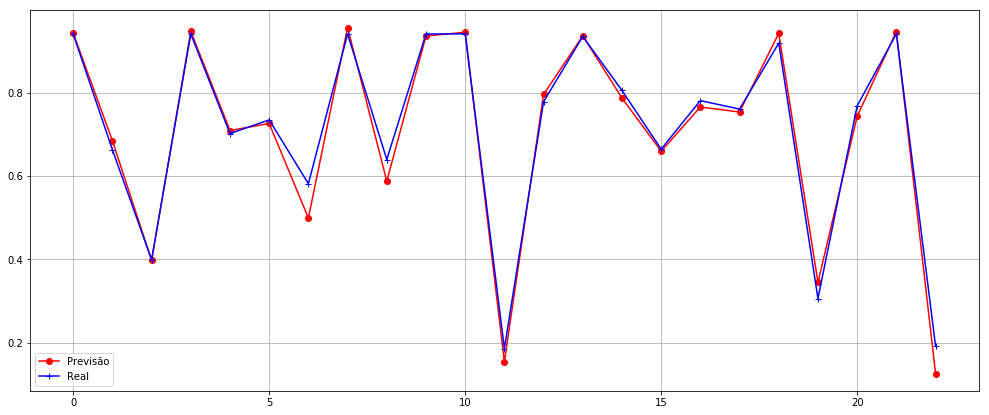

In [87]:
#CÉLULA TCC-
RandomForest = RandomForestRegressor(n_estimators=350, random_state=0)
    
print('----------------------------------------------------')
print('------------      RANDOM FOREST     ----------------')
print('----------------------------------------------------')

modelRandomForest = showResult(RandomForest, X_train, y_train, X_test, y_test)

In [56]:
#MAE é a média da diferença absoluta entre os valores previstos e o valor observado

#O numerador é MSE (média dos quadrados dos residuais) e o denominador é a variância nos valores Y. Quanto mais alto o MSE, menor o R_squared e mais pobre é o modelo.

#Por que você deve escolher R² Ajustado sobre R²?
#Existem alguns problemas com o R² normal que são resolvidos pelo R² Ajustado. Um R² ajustado considerará a melhoria marginal adicionada por um termo adicional em seu modelo. Por isso, aumentará se você adicionar os termos úteis e diminuirá se você adicionar preditores menos úteis. No entanto, o R² aumenta com termos crescentes, mesmo que o modelo não esteja realmente melhorando.

#O R², também chamado de Coeficiente de Determinação, diz o quanto meu modelo está prevendo corretamente.

#RMSE (Root Mean Square Error)(Erro Quadrado Médio da Raiz)
#Representa o desvio padrão da amostra das diferenças entre os valores previstos e os valores observados (chamados resíduos)

In [57]:
#Teste F de Significância global: afirma se ao menos uma variável do meu modelo está relacionada com a variável alvo. Para isso, o valor-p desta estatística precisa ser menor que 0.05

#Teste de Significância individuais ou p-values dos coeficientes: diz o quanto das variáveis preditoras explicam a variável alvo. A métrica padrão é o p-value ser menor que 0.05.

#Coeficiente R²: diz o quanto o meu modelo explica seus resultados. É um valor entre 0 e 1. Quanto mais próximo de 1, melhor.

In [58]:
%matplotlib inline
import matplotlib.pyplot as plt

import numpy as np
import seaborn as sns

def plot_residuals_and_coeff(resid_train, resid_test, coeff):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3))
    axes[0].bar(np.arange(len(resid_train)), resid_train)
    axes[0].set_xlabel("núm. amostras")
    axes[0].set_ylabel("resíduo")
    axes[0].set_title("treino")
    axes[1].bar(np.arange(len(resid_test)), resid_test)
    axes[1].set_xlabel("núm. amostras")
    axes[1].set_ylabel("resíduo")
    axes[1].set_title("teste")
    axes[2].bar(np.arange(len(coeff)), coeff)
    axes[2].set_xlabel("núm. coeficientes")
    axes[2].set_ylabel("coeficiente")
    fig.tight_layout()
    return fig, axes

residuo_treino = y_train - modelRegLinear.predict(X_train)
residuo_teste  = y_test - modelRegLinear.predict(X_test)

fig, ax = plot_residuals_and_coeff(residuo_treino, residuo_teste, modelRegLinear.coef_)

NameError: name 'modelRegLinear' is not defined

In [ ]:
from sklearn.linear_model import Lasso
from sklearn.linear_model import LinearRegression
from pandas import Series, DataFrame

lasso = Lasso()
lasso.fit(X_train,y_train)
train_score=lasso.score(X_train,y_train)
test_score=lasso.score(X_test,y_test)
coeff_used = np.sum(lasso.coef_!=0)

print("training score:" , train_score)
print("test score: " , test_score)
print("number of features used: ", coeff_used)

lasso001 = Lasso(alpha=0.01, max_iter=10e5)
lasso001.fit(X_train,y_train)

train_score001=lasso001.score(X_train,y_train)
test_score001=lasso001.score(X_test,y_test)
coeff_used001 = np.sum(lasso001.coef_!=0)

print("training score for alpha=0.01:", train_score001)
print("test score for alpha =0.01: ", test_score001)
print("number of features used: for alpha =0.01:", coeff_used001)

lasso00001 = Lasso(alpha=0.0001, max_iter=10e5)
lasso00001.fit(X_train,y_train)

train_score00001=lasso00001.score(X_train,y_train)
test_score00001=lasso00001.score(X_test,y_test)
coeff_used00001 = np.sum(lasso00001.coef_!=0)

print("training score for alpha=0.0001:", train_score00001)
print("test score for alpha =0.0001: ", test_score00001)
print("number of features used: for alpha =0.0001:", coeff_used00001)

lr = LinearRegression()
lr.fit(X_train,y_train)
lr_train_score=lr.score(X_train,y_train)
lr_test_score=lr.score(X_test,y_test)

print("LR training score:", lr_train_score)
print("LR test score: ", lr_test_score)

plt.subplot(1,2,1)
plt.plot(lasso.coef_,alpha=0.7,linestyle='none',marker='*',markersize=5,color='red',label=r'Lasso; $\alpha = 1$',zorder=7) # alpha here is for transparency
plt.plot(lasso001.coef_,alpha=0.5,linestyle='none',marker='d',markersize=6,color='blue',label=r'Lasso; $\alpha = 0.01$') # alpha here is for transparency

plt.xlabel('Coefficient Index',fontsize=16)
plt.ylabel('Coefficient Magnitude',fontsize=16)
plt.legend(fontsize=13,loc=4)

plt.subplot(1,2,2)

plt.plot(lasso.coef_,alpha=0.7,linestyle='none',marker='*',markersize=5,color='red',label=r'Lasso; $\alpha = 1$',zorder=7) # alpha here is for transparency
plt.plot(lasso001.coef_,alpha=0.5,linestyle='none',marker='d',markersize=6,color='blue',label=r'Lasso; $\alpha = 0.01$') # alpha here is for transparency
plt.plot(lasso00001.coef_,alpha=0.8,linestyle='none',marker='v',markersize=6,color='black',label=r'Lasso; $\alpha = 0.00001$') # alpha here is for transparency
plt.plot(lr.coef_,alpha=0.7,linestyle='none',marker='o',markersize=5,color='green',label='Linear Regression',zorder=2)

plt.xlabel('Coefficient Index',fontsize=16)
plt.ylabel('Coefficient Magnitude',fontsize=16)
plt.legend(fontsize=13,loc=4)
plt.tight_layout()
plt.show()

## 4 - Otimização

## 5 - Resultados

In [ ]:


from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
regressor = RandomForestRegressor(n_estimators = 100)
regressor.fit(X_train, y_train)
feature_importances = regressor.feature_importances_

X_train_opt = X_train.copy()
removed_columns = pd.DataFrame()
models = []
r2s_opt = []

for i in range(0,5):
    least_important = np.argmin(feature_importances)
    removed_columns = removed_columns.append(X_train_opt.pop(X_train_opt.columns[least_important]))
    regressor.fit(X_train_opt, y_train)
    feature_importances = regressor.feature_importances_
    accuracies = cross_val_score(estimator = regressor,
                                 X = X_train_opt,
                                 y = y_train, cv = 5,
                                 scoring = 'r2')
    r2s_opt = np.append(r2s_opt, accuracies.mean())
    models = np.append(models, ", ".join(list(X_train_opt)))
    
feature_selection = pd.DataFrame({'Features':models,'r2 Score':r2s_opt})
feature_selection.head()

